In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.base import clone

os.makedirs("medical_output", exist_ok=True)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
data = load_breast_cancer(as_frame=True)

X = data.data.copy()

# Convert target: 1 = malignant, 0 = benign
y = (data.target == 0).astype(int)

print("Dataset shape:", X.shape)
print("Features:", X.shape[1])
print("\nClass counts:")
print(y.value_counts().rename(index={0: "Benign", 1: "Malignant"}))

display(X.head())

Dataset shape: (569, 30)
Features: 30

Class counts:
target
Benign       357
Malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:
print("Missing values in each feature:")
print(X.isnull().sum().sort_values(ascending=False).head(10))

print("\nDuplicate rows:", X.duplicated().sum())

print("\nTarget distribution:")
print(y.value_counts(normalize=True).mul(100).round(2))

Missing values in each feature:
mean radius               0
mean texture              0
mean perimeter            0
mean area                 0
mean smoothness           0
mean compactness          0
mean concavity            0
mean concave points       0
mean symmetry             0
mean fractal dimension    0
dtype: int64

Duplicate rows: 0

Target distribution:
target
0    62.74
1    37.26
Name: proportion, dtype: float64


In [ ]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=5000,
        class_weight="balanced"
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

results = {}
fold_results = []

for name, model in models.items():
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    scores = cross_validate(
        pipe, X, y,
        cv=cv,
        scoring=scoring,
        return_train_score=False
    )

    results[name] = {
        metric: (
            scores[f"test_{metric}"].mean(),
            scores[f"test_{metric}"].std()
        )
        for metric in scoring
    }

    for fold in range(5):
        row = {"Model": name, "Fold": fold + 1}
        for metric in scoring:
            row[metric] = scores[f"test_{metric}"][fold]
        fold_results.append(row)

print("Cross-validation completed!")

Cross-validation completed!


In [ ]:
rows = []

for name, metrics in results.items():
    row = {"Model": name}

    for metric, (mean, std) in metrics.items():
        row[metric] = f"{mean:.3f} ± {std:.3f}"

    rows.append(row)

comparison = pd.DataFrame(rows).sort_values(
    "roc_auc", ascending=False
)

display(comparison)

comparison.to_csv(
    "medical_output/model_comparison.csv",
    index=False
)

,Model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.972 ± 0.013,0.968 ± 0.022,0.958 ± 0.034,0.962 ± 0.018,0.995 ± 0.005
2,Random Forest,0.960 ± 0.015,0.956 ± 0.043,0.939 ± 0.055,0.945 ± 0.021,0.991 ± 0.007
1,Decision Tree,0.926 ± 0.004,0.904 ± 0.039,0.901 ± 0.043,0.901 ± 0.006,0.921 ± 0.009


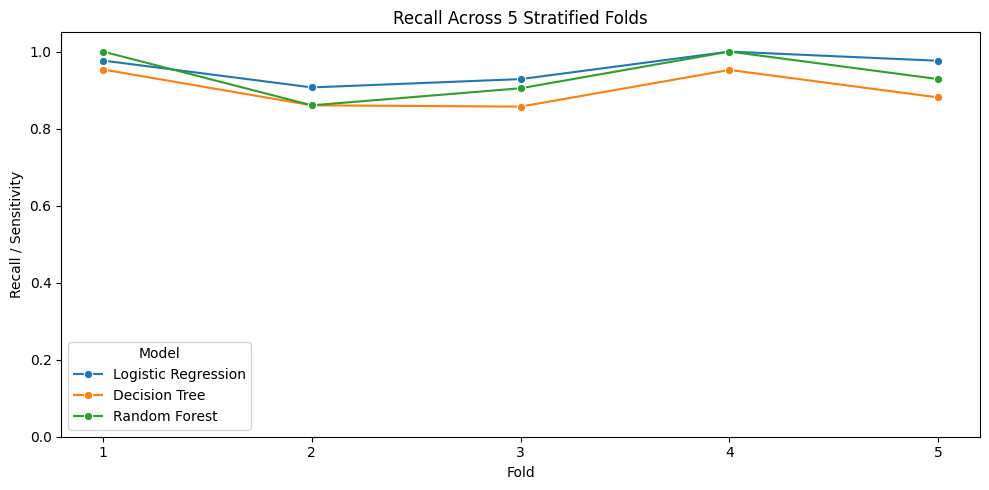

In [ ]:
fold_df = pd.DataFrame(fold_results)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=fold_df,
    x="Fold",
    y="recall",
    hue="Model",
    marker="o"
)

plt.title("Recall Across 5 Stratified Folds")
plt.ylabel("Recall / Sensitivity")
plt.xticks([1, 2, 3, 4, 5])
plt.ylim(0, 1.05)
plt.tight_layout()
plt.savefig("medical_output/fold_recall.png", dpi=150)
plt.show()

In [ ]:
best_name = max(
    results,
    key=lambda name: results[name]["roc_auc"][0]
)

print("Best model by mean CV ROC-AUC:", best_name)
print("Mean ROC-AUC:", round(results[best_name]["roc_auc"][0], 4))
print("Mean Recall:", round(results[best_name]["recall"][0], 4))

Best model by mean CV ROC-AUC: Logistic Regression
Mean ROC-AUC: 0.9951
Mean Recall: 0.9577


In [ ]:
best_name = max(
    results,
    key=lambda name: results[name]["roc_auc"][0]
)

print("Best model by mean CV ROC-AUC:", best_name)
print("Mean ROC-AUC:", round(results[best_name]["roc_auc"][0], 4))
print("Mean Recall:", round(results[best_name]["recall"][0], 4))

Best model by mean CV ROC-AUC: Logistic Regression
Mean ROC-AUC: 0.9951
Mean Recall: 0.9577


Out-of-fold evaluation
Accuracy: 0.9719
Precision: 0.9667
Recall: 0.9575
F1-score: 0.9621
ROC-AUC: 0.9943


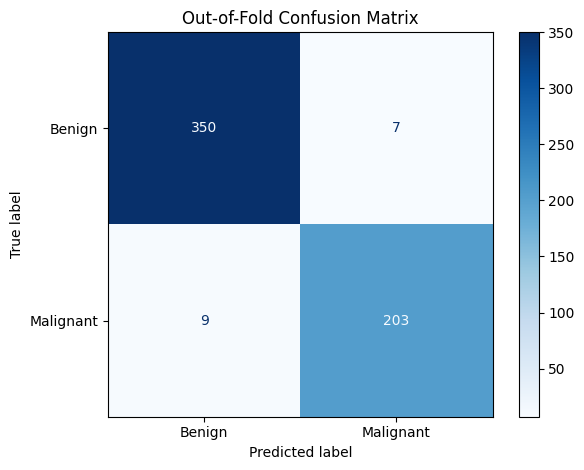

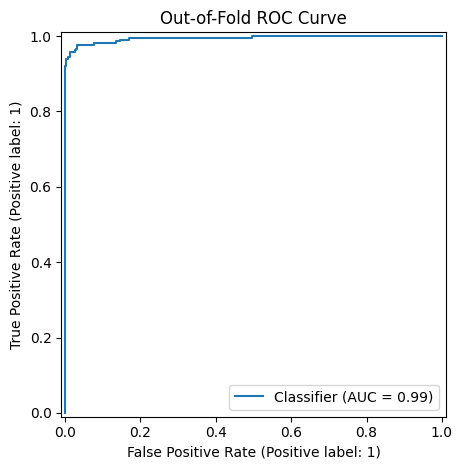

In [ ]:
from sklearn.model_selection import cross_val_predict

best_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", clone(models[best_name]))
])

oof_pred = cross_val_predict(
    best_pipe, X, y,
    cv=cv,
    method="predict"
)

oof_prob = cross_val_predict(
    best_pipe, X, y,
    cv=cv,
    method="predict_proba"
)[:, 1]

print("Out-of-fold evaluation")
print("Accuracy:", round(accuracy_score(y, oof_pred), 4))
print("Precision:", round(precision_score(y, oof_pred), 4))
print("Recall:", round(recall_score(y, oof_pred), 4))
print("F1-score:", round(f1_score(y, oof_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y, oof_prob), 4))

cm = confusion_matrix(y, oof_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
).plot(cmap="Blues")

plt.title("Out-of-Fold Confusion Matrix")
plt.tight_layout()
plt.savefig("medical_output/confusion_matrix.png", dpi=150)
plt.show()

RocCurveDisplay.from_predictions(y, oof_prob)
plt.title("Out-of-Fold ROC Curve")
plt.tight_layout()
plt.savefig("medical_output/roc_curve.png", dpi=150)
plt.show()

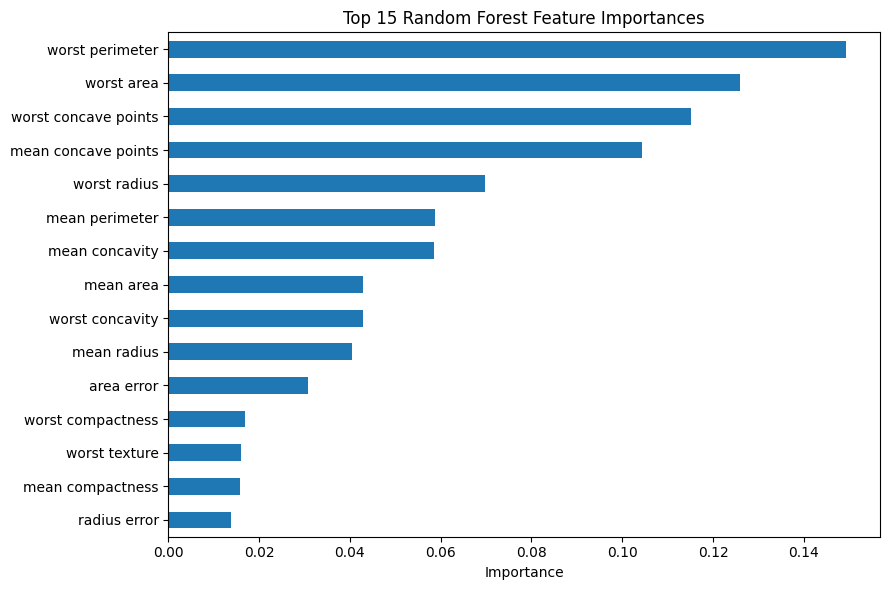

In [ ]:
rf_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    ))
])

rf_pipe.fit(X, y)

importance = pd.Series(
    rf_pipe.named_steps["model"].feature_importances_,
    index=X.columns
).sort_values(ascending=False).head(15)

importance.sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("medical_output/feature_importance.png", dpi=150)
plt.show()

importance.to_csv("medical_output/feature_importance.csv")

In [ ]:
report = f"""
MEDICAL DIAGNOSIS CLASSIFIER WITH CROSS-VALIDATION
=================================================

Dataset: Breast Cancer Wisconsin
Samples: {len(X)}
Features: {X.shape[1]}
Validation: 5-fold Stratified Cross-Validation

BEST MODEL BY MEAN CV ROC-AUC
-----------------------------
Model: {best_name}
Mean ROC-AUC: {results[best_name]['roc_auc'][0]:.4f}
ROC-AUC standard deviation: {results[best_name]['roc_auc'][1]:.4f}
Mean recall: {results[best_name]['recall'][0]:.4f}
Recall standard deviation: {results[best_name]['recall'][1]:.4f}

OUT-OF-FOLD METRICS
-------------------
Accuracy: {accuracy_score(y, oof_pred):.4f}
Precision: {precision_score(y, oof_pred):.4f}
Recall: {recall_score(y, oof_pred):.4f}
F1-score: {f1_score(y, oof_pred):.4f}
ROC-AUC: {roc_auc_score(y, oof_prob):.4f}

WHY CROSS-VALIDATION MATTERS
----------------------------
A single train-test split can give an unstable estimate depending on
which samples are selected. Stratified cross-validation preserves
the class proportions in each fold and shows how performance varies.

MEDICAL AND ETHICAL CONSIDERATIONS
----------------------------------
Recall measures the proportion of actual positive cases detected.
Low recall can mean false negatives, which may delay further testing.
False positives can cause anxiety and unnecessary follow-up tests.
Precision, recall, ROC-AUC, calibration, and clinical consequences
must all be considered rather than relying on accuracy alone.

LIMITATIONS
-----------
This is an educational dataset and not a clinically validated system.
Results from cross-validation do not establish real-world clinical
safety. External validation, expert review, privacy safeguards, and
careful threshold selection are needed before clinical use.
"""

with open("medical_output/medical_diagnosis_report.txt", "w") as f:
    f.write(report)

print(report)


MEDICAL DIAGNOSIS CLASSIFIER WITH CROSS-VALIDATION

Dataset: Breast Cancer Wisconsin
Samples: 569
Features: 30
Validation: 5-fold Stratified Cross-Validation

BEST MODEL BY MEAN CV ROC-AUC
-----------------------------
Model: Logistic Regression
Mean ROC-AUC: 0.9951
ROC-AUC standard deviation: 0.0055
Mean recall: 0.9577
Recall standard deviation: 0.0344

OUT-OF-FOLD METRICS
-------------------
Accuracy: 0.9719
Precision: 0.9667
Recall: 0.9575
F1-score: 0.9621
ROC-AUC: 0.9943

WHY CROSS-VALIDATION MATTERS
----------------------------
A single train-test split can give an unstable estimate depending on
which samples are selected. Stratified cross-validation preserves
the class proportions in each fold and shows how performance varies.

MEDICAL AND ETHICAL CONSIDERATIONS
----------------------------------
Recall measures the proportion of actual positive cases detected.
Low recall can mean false negatives, which may delay further testing.
False positives can cause anxiety and unnecessary

In [ ]:
import zipfile
from google.colab import files

fold_df.to_csv("medical_output/fold_scores.csv", index=False)

with zipfile.ZipFile(
    "Medical_Diagnosis_Project.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as z:
    for root, dirs, filenames in os.walk("medical_output"):
        for filename in filenames:
            path = os.path.join(root, filename)
            z.write(path, arcname=path)

files.download("Medical_Diagnosis_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>